<a href="https://colab.research.google.com/github/samnocera05-ui/mis433/blob/main/Copy_of_assignment_IMDB_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment - Analyzing the IMDB Top 1000 Movies

In this assignment, you will be working with this dataset of IMDB top 1000 movies.

Source: https://www.kaggle.com/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Read the data file "imdb_top_1000.csv" to a dataframe named "imdb"
imdb = pd.read_csv('https://raw.githubusercontent.com/jiexunli-wwu/mis433/refs/heads/main/data/imdb_top_1000.csv', header=0)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [3]:
# Describe the dataframe using the info() method.
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [4]:
# List all the column names:
imdb.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')

## Part 1: Data Manipulation

Redo the following to clean the data.

In [30]:
# Count the number of movies in each "Released_Year".
# Hint: value_counts()
imdb.Released_Year.value_counts()

,count
Released_Year,
2014,32
2004,31
2009,29
2013,28
2016,28
...,...
1920,1
1930,1
1922,1


In [32]:
# In this dataset, there is a movie with an error in "Released_Year".
# Hint: Released_Year should be a 4-digit integer but this movie's year is not.
# Find this movie.
imdb[imdb.Released_Year.str.len() != 4]

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,https://m.media-amazon.com/images/M/MV5BNjEzYj...,Apollo 13,PG,U,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [33]:
# Correct the values for the corresponding columns ("Released_Year" and "Certificate").
# You may want to look up this movie on www.imdb.com.
# Hint: You can set value for a particular row by: df.loc[row_index, column_name] = new_value
imdb.loc[966, 'Released_Year'] = '1995'
imdb.loc[966, 'Certificate'] = 'PG'

In [34]:
# Change the data type of "Released_Year" to int
imdb['Released_Year'] = pd.to_numeric(imdb['Released_Year']).astype(int)

In [36]:
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >=8.5)][['Series_Title', 'Released_Year', 'Certificate', 'Gross']].sort_values('Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
19,Gisaengchung,2019,A,"53,367,844"
33,Joker,2019,A,"335,451,311"
8,Inception,2010,UA,"292,576,195"
21,Interstellar,2014,UA,"188,020,017"
35,The Intouchables,2011,UA,"13,182,281"
34,Whiplash,2014,A,"13,092,000"
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [10]:
# Does the sorting result look right to you? What's the problem?
#

In [37]:
# Resolve this problem of "Gross" and convert its data type to float
# Hint: You may find this webpage useful:
# https://stackoverflow.com/questions/28986489/how-to-replace-text-in-a-column-of-a-pandas-dataframe
imdb['Gross'] = imdb['Gross'].str.replace(',', '').astype(float)

In [38]:
# Next, redo the sorting on Gross

# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >=8.5)][['Series_Title', 'Released_Year', 'Certificate', 'Gross']].sort_values('Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
33,Joker,2019,A,335451311.0
8,Inception,2010,UA,292576195.0
21,Interstellar,2014,UA,188020017.0
19,Gisaengchung,2019,A,53367844.0
35,The Intouchables,2011,UA,13182281.0
34,Whiplash,2014,A,13092000.0
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [39]:
# Add a new column "Runtime_min" by removing the substring " min" in "Runtime"
# Set its data type as int
# Hint: https://stackoverflow.com/questions/36505847/substring-of-an-entire-column-in-pandas-dataframe
imdb['Runtime_min'] = imdb['Runtime'].str.replace('min', '').astype(int)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_min
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0,202
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0,96


In [40]:
# Add a new column "Age_Years" by the expression: Current year - Released_Year
imdb['Age_Years'] = 2026 - imdb['Released_Year']

In [41]:
# Add a new column "Decade" with values as 1980, 1990, 2000, 2010, 2020, etc.
imdb['Decade'] = (imdb['Released_Year'] // 10) * 10

## Part 2: Data Summarization

Done!

## Part 3: Data Visualization

Finish Part 1 (data manipulation) before you work through this section.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='IMDB_Rating', ylabel='Meta_score'>

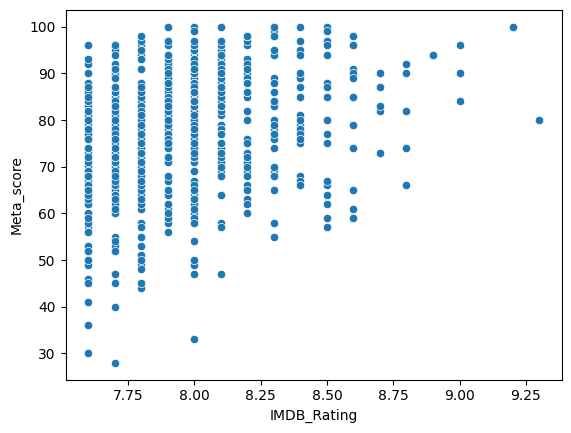

In [44]:
# Create a scatterplot of the two scores, "IMDB_Rating" and "Meta_score".
# In a sentence or two, describe what this pair of scores suggests about the movies.
sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score')
# The chart suggests that there is a correlation between IMDB_Ratings and Meta_scores. The idea that as IMDB_Ratings increase, Meta_score tends to increase as well, indicating that audiencies and critics generally agree on overall quality.

<Axes: xlabel='IMDB_Rating', ylabel='Meta_score'>

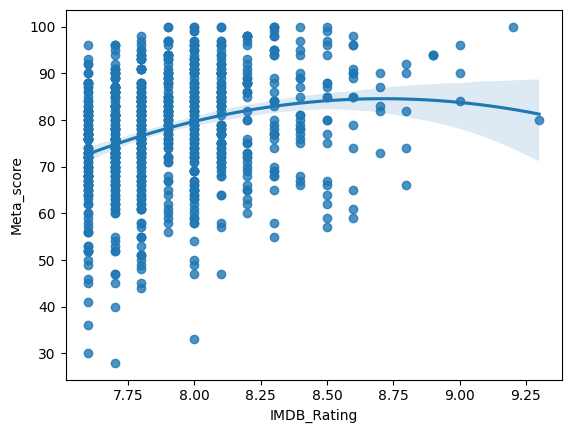

In [51]:
# Fit a trendline to show the relationship between the two scores.
# Hint: sns.regplot()
# Try a few values of the `order` argument (polynomial degree) for the trendline.
sns.regplot(data=imdb, x='IMDB_Rating', y='Meta_score', order=2)

In [56]:
# Do any data points in the scatterplot surprise you?
# Try to identify a few such movies.
imdb[(imdb.IMDB_Rating < 8.0) & (imdb.Meta_score > 95)]

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_min,Age_Years,Decade
491,https://m.media-amazon.com/images/M/MV5BMTYzND...,Boyhood,2014,A,165 min,Drama,7.9,"The life of Mason, from early childhood to his...",100.0,Richard Linklater,Ellar Coltrane,Patricia Arquette,Ethan Hawke,Elijah Smith,335533,25379975.0,165,12,2010
492,https://m.media-amazon.com/images/M/MV5BYzU1YW...,"4 luni, 3 saptamâni si 2 zile",2007,NaN,113 min,Drama,7.9,A woman assists her friend in arranging an ill...,97.0,Cristian Mungiu,Anamaria Marinca,Laura Vasiliu,Vlad Ivanov,Alexandru Potocean,56625,1185783.0,113,19,2000
525,https://m.media-amazon.com/images/M/MV5BYjdkNz...,My Left Foot: The Story of Christy Brown,1989,U,103 min,"Biography, Drama",7.9,"Christy Brown, born with cerebral palsy, learn...",97.0,Jim Sheridan,Daniel Day-Lewis,Brenda Fricker,Alison Whelan,Kirsten Sheridan,68076,14743391.0,103,37,1980
543,https://m.media-amazon.com/images/M/MV5BNGUyYT...,The Wild Bunch,1969,A,145 min,"Action, Adventure, Western",7.9,An aging group of outlaws look for one last bi...,97.0,Sam Peckinpah,William Holden,Ernest Borgnine,Robert Ryan,Edmond O'Brien,77401,12064472.0,145,57,1960
559,https://m.media-amazon.com/images/M/MV5BYTc1NG...,Notorious,1946,U,102 min,"Drama, Film-Noir, Romance",7.9,A woman is asked to spy on a group of Nazi fri...,100.0,Alfred Hitchcock,Cary Grant,Ingrid Bergman,Claude Rains,Louis Calhern,92306,10464000.0,102,80,1940
562,https://m.media-amazon.com/images/M/MV5BYjQ4ZD...,The Philadelphia Story,1940,NaN,112 min,"Comedy, Romance",7.9,When a rich woman's ex-husband and a tabloid-t...,96.0,George Cukor,Cary Grant,Katharine Hepburn,James Stewart,Ruth Hussey,63550,NaN,112,86,1940
564,https://m.media-amazon.com/images/M/MV5BYjZjOT...,The Adventures of Robin Hood,1938,PG,102 min,"Action, Adventure, Romance",7.9,When Prince John and the Norman Lords begin op...,97.0,Michael Curtiz,William Keighley,Errol Flynn,Olivia de Havilland,Basil Rathbone,47175,3981000.0,102,88,1930
580,https://m.media-amazon.com/images/M/MV5BMTYxMj...,Manchester by the Sea,2016,UA,137 min,Drama,7.8,A depressed uncle is asked to take care of his...,96.0,Kenneth Lonergan,Casey Affleck,Michelle Williams,Kyle Chandler,Lucas Hedges,246963,47695120.0,137,10,2010
706,https://m.media-amazon.com/images/M/MV5BZTM1MT...,Jules et Jim,1962,NaN,105 min,"Drama, Romance",7.8,Decades of a love triangle concerning two frie...,97.0,François Truffaut,Jeanne Moreau,Oskar Werner,Henri Serre,Vanna Urbino,37605,NaN,105,64,1960
714,https://m.media-amazon.com/images/M/MV5BNjk3Yz...,The Lady Vanishes,1938,NaN,96 min,"Mystery, Thriller",7.8,"While travelling in continental Europe, a rich...",98.0,Alfred Hitchcock,Margaret Lockwood,Michael Redgrave,Paul Lukas,May Whitty,47400,NaN,96,88,1930


<Axes: xlabel='IMDB_Rating', ylabel='Meta_score'>

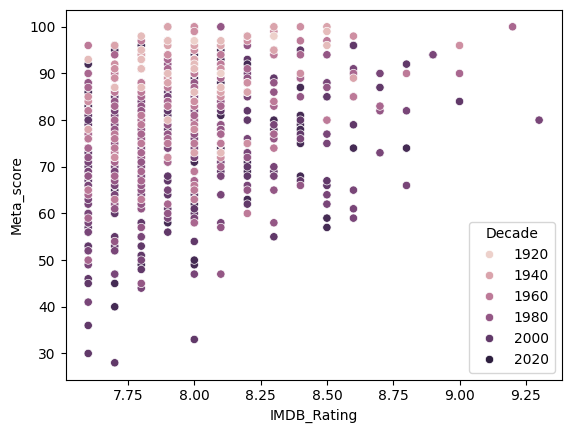

In [59]:
# In the scatterplot, use color to distinguish movies from different decades.
sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score', hue = 'Decade')


<Axes: xlabel='Decade', ylabel='count'>

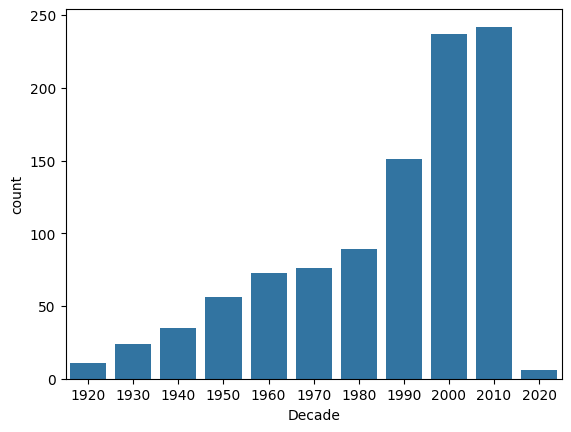

In [60]:
# Create a chart that shows how many movies fall into each decade.
sns.countplot(data=imdb, x='Decade')

<Axes: ylabel='count'>

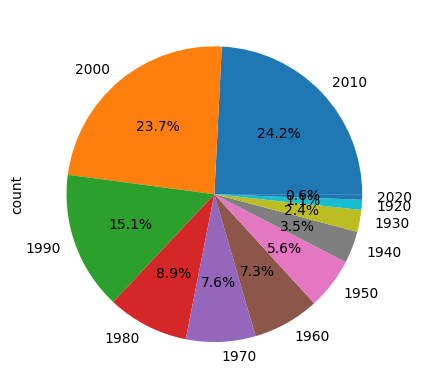

In [66]:
# Create a chart that shows the percentage of movies in each decade.
imdb.Decade.value_counts().plot.pie(autopct='%1.1f%%')

<Axes: xlabel='Director'>

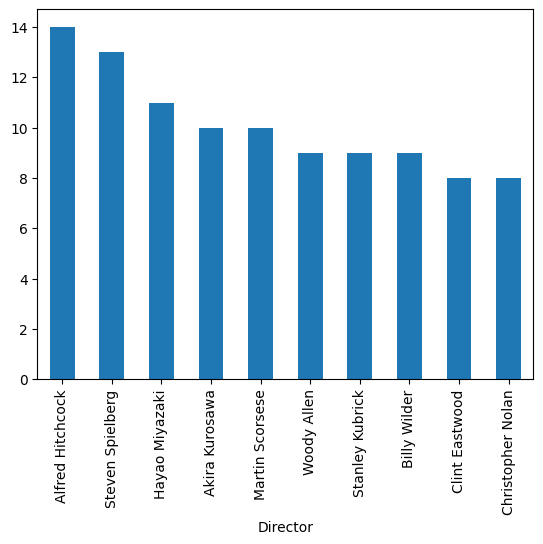

In [73]:
# Count movies by director.
# Show the top 10 directors by movie count in a bar chart.
top_10_directors = imdb.Director.value_counts().head(10)
top_10_directors.plot.bar()

<Axes: xlabel='IMDB_Rating', ylabel='Gross'>

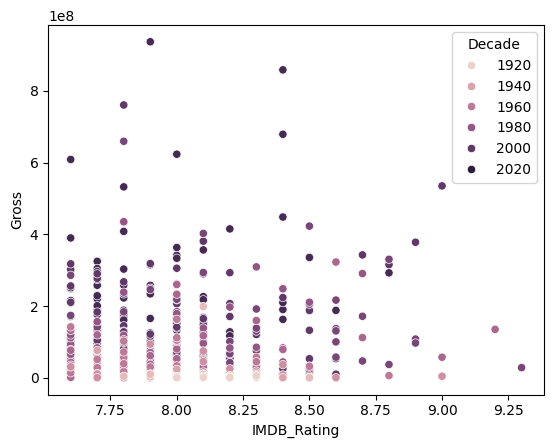

In [74]:
# Create a scatterplot of "IMDB_Rating" and "Gross".
# Use color to distinguish movies from different decades.
# Briefly interpret what the chart shows.
sns.scatterplot(data=imdb, x = 'IMDB_Rating', y = 'Gross', hue = 'Decade')
# higher imdb rating don't necessarily lead to higher gross. Movies from more recent decades also seem to have higher gross values.

<Axes: ylabel='count'>

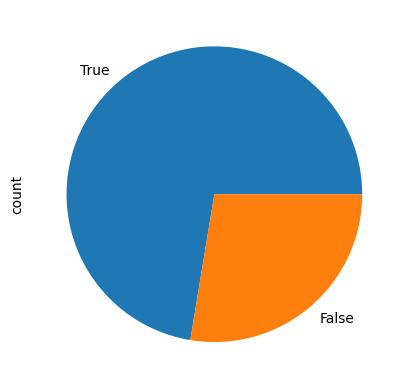

In [77]:
# Create a column named "Drama" that indicates whether a movie's Genre includes "Drama".
# Create a pie chart showing the share of drama vs. non-drama movies.
imdb['Drama'] = imdb.Genre.str.contains('Drama')
imdb.Drama.value_counts().plot.pie()

<Axes: xlabel='Decade', ylabel='Gross'>

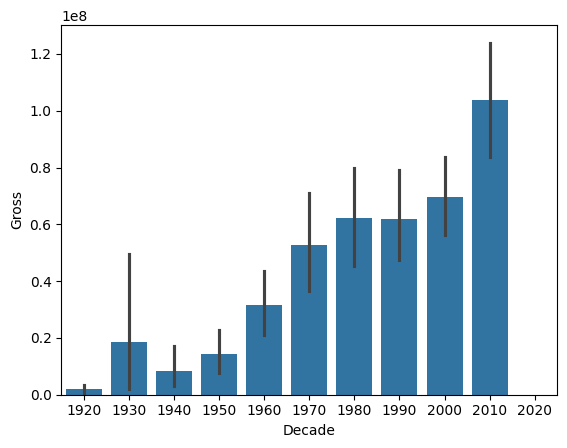

In [80]:
# Create a plot comparing Gross across decades.
sns.barplot(data=imdb, x = 'Decade', y = 'Gross')

<Axes: xlabel='Gross', ylabel='Count'>

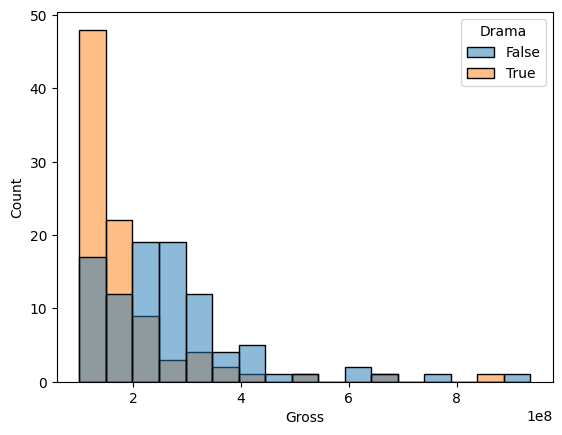

In [81]:
# For movies with Gross over $100 million:
# Create a histogram of Gross for drama vs. non-drama movies.
gross_100M = imdb[imdb.Gross > 100000000]
sns.histplot(data=gross_100M, x = 'Gross', hue = 'Drama')

<Axes: xlabel='Genre'>

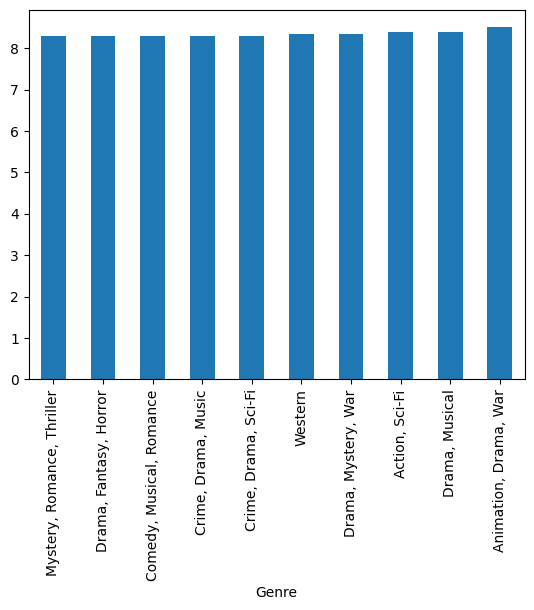

In [82]:
# Come up with two more questions about this dataset. Create one chart or figure for each.
# Question 1: Which genres have the highest average IMDB rating?
imdb.groupby('Genre')['IMDB_Rating'].mean().sort_values().tail(10).plot.bar()

<Axes: xlabel='Decade', ylabel='Runtime'>

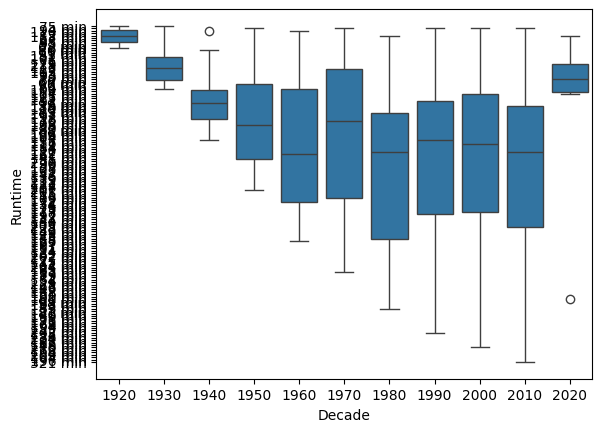

In [88]:
# Question 2: “How does runtime vary across decades?
imdb_across_decades = imdb.sort_values('Decade')
sns.boxplot(data=imdb_across_decades, x=imdb_across_decades.Decade.astype(str), y='Runtime')